# Importing the libraries and dependencies

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder,LabelEncoder


# Importing the dataset

In [7]:
ecomDf = pd.read_csv('../DataSets/shop_smart_ecommerce.csv')
ecomDf.info()
ecomDf.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
10665,10,779.450,0,0.0,39,1002.491667,0.018750,0.033796,0.0,0.0,Nov,3,2,1,3,Returning_Visitor,False,False
10110,4,140.475,1,0.0,48,1252.561414,0.014038,0.024739,0.0,0.0,Nov,3,2,1,2,Returning_Visitor,True,False
201,0,0.000,0,0.0,5,43.000000,0.000000,0.040000,0.0,0.0,Mar,1,1,1,9,Returning_Visitor,True,False
5181,0,0.000,0,0.0,27,589.573810,0.007407,0.005556,0.0,0.0,May,3,2,3,4,Returning_Visitor,True,False
2166,0,0.000,0,0.0,8,149.000000,0.133333,0.155556,0.0,0.8,May,2,2,7,3,Returning_Visitor,False,False


In [10]:
ecomDf.isnull().sum()
ecomDf['VisitorType'].unique()

array(['Returning_Visitor', 'New_Visitor', 'Other'], dtype=object)

#  Encoding categorical columns

In [11]:
#Label encoding for 'Month' column
le = LabelEncoder()
ecomDf['Month'] = le.fit_transform(ecomDf['Month'])
ecomDf.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,Returning_Visitor,True,False


In [16]:
#One-hot encoding 'VisitorType' column
ohe= OneHotEncoder(drop="first", sparse_output=False,handle_unknown='ignore')
encoded_data = ohe.fit_transform(ecomDf[['VisitorType']])
encoded_df = pd.DataFrame(
    encoded_data, 
    columns=ohe.get_feature_names_out(['VisitorType']),
    index=ecomDf.index # Important: keeps the index aligned with the original dataframe
)
ecomDf = pd.concat([ecomDf.drop('VisitorType', axis=1), encoded_df], axis=1)

In [17]:
ecomDf.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,False,False,0.0,1.0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,False,False,0.0,1.0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,False,False,0.0,1.0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,False,False,0.0,1.0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,True,False,0.0,1.0


In [18]:
ecomDf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Administrative                 12330 non-null  int64  
 1   Administrative_Duration        12330 non-null  float64
 2   Informational                  12330 non-null  int64  
 3   Informational_Duration         12330 non-null  float64
 4   ProductRelated                 12330 non-null  int64  
 5   ProductRelated_Duration        12330 non-null  float64
 6   BounceRates                    12330 non-null  float64
 7   ExitRates                      12330 non-null  float64
 8   PageValues                     12330 non-null  float64
 9   SpecialDay                     12330 non-null  float64
 10  Month                          12330 non-null  int64  
 11  OperatingSystems               12330 non-null  int64  
 12  Browser                        12330 non-null 

# Model training 

In [20]:
X = ecomDf.drop(columns=['Revenue'])
y = ecomDf['Revenue']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

print(f"F1 score : {f1_score(y_test,y_pred)}")

F1 score : 0.5821256038647343


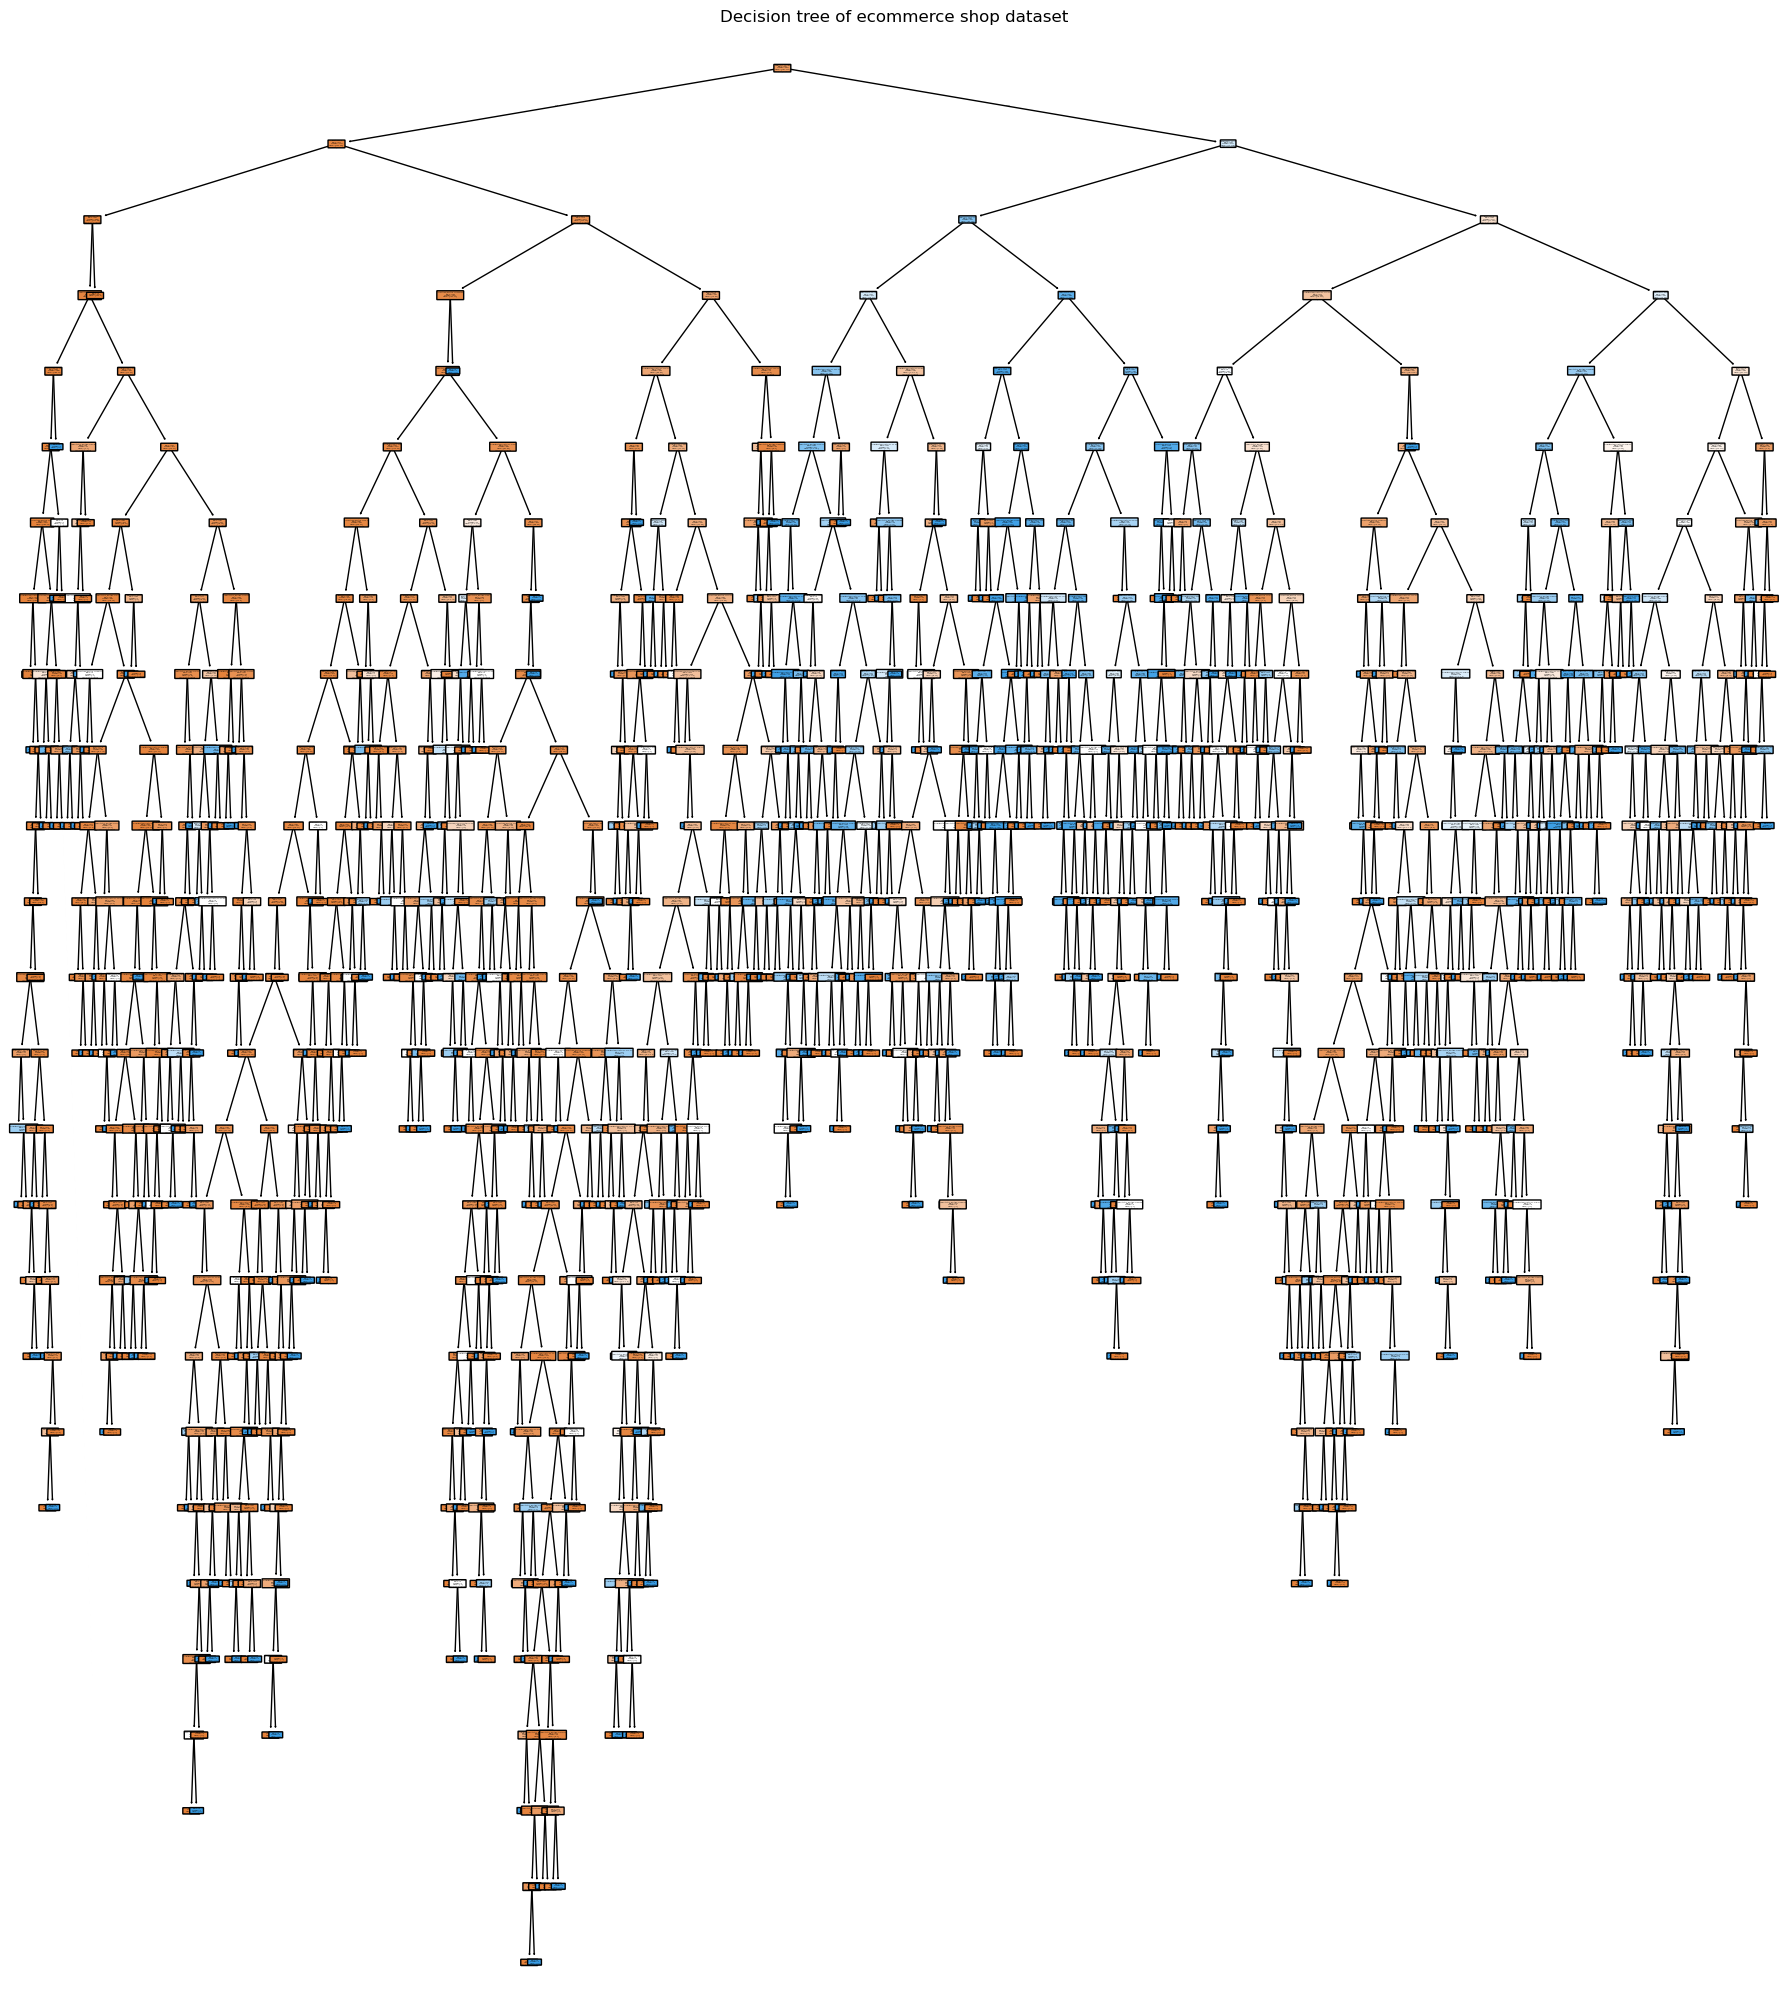

In [24]:
from  sklearn.tree import plot_tree

plt.figure(figsize=(18,20))
plot_tree(model, feature_names=X.columns , class_names=['Not_purchased','Purchased'],filled=True, rounded= True)
plt.tight_layout()
plt.title("Decision tree of ecommerce shop dataset")
plt.show()

# Pre-pruning the model

In [31]:
depths = [2,3,4,5,6,7,8,9,10,11,12,13,14,15]
max_f1 = 0
best_depth= 0
for depth in depths:
    dummymodel = DecisionTreeClassifier(max_depth= depth)
    dummymodel.fit(X_train,y_train)
    f1s = f1_score(y_test,dummymodel.predict(X_test))
    print(f"For depth = {depth} , f1 score = {f1s}")
    if max_f1 < f1s:
        max_f1 = f1s
        best_depth = depth

For depth = 2 , f1 score = 0.5256609642301711
For depth = 3 , f1 score = 0.6436781609195402
For depth = 4 , f1 score = 0.6308724832214765
For depth = 5 , f1 score = 0.5744047619047619
For depth = 6 , f1 score = 0.6246648793565683
For depth = 7 , f1 score = 0.6179310344827587
For depth = 8 , f1 score = 0.6293706293706294
For depth = 9 , f1 score = 0.603042876901798
For depth = 10 , f1 score = 0.6040268456375839
For depth = 11 , f1 score = 0.6104417670682731
For depth = 12 , f1 score = 0.5955786736020806
For depth = 13 , f1 score = 0.599483204134367
For depth = 14 , f1 score = 0.5977011494252874
For depth = 15 , f1 score = 0.5989974937343359


In [34]:
splits = [20,25,30,35,40,45,50,55,60]
max_f1 = 0
best_split= 0
for split in splits:
    dummymodel = DecisionTreeClassifier(min_samples_split=split)
    dummymodel.fit(X_train,y_train)
    f1s = f1_score(y_test,dummymodel.predict(X_test))
    print(f"For split = {split} , f1 score = {f1s}")
    if max_f1 < f1s:
        max_f1 = f1s
        best_split = split

For split = 20 , f1 score = 0.6251556662515566
For split = 25 , f1 score = 0.6141935483870967
For split = 30 , f1 score = 0.6181818181818182
For split = 35 , f1 score = 0.6203346203346203
For split = 40 , f1 score = 0.6186107470511141
For split = 45 , f1 score = 0.6201342281879194
For split = 50 , f1 score = 0.6141304347826086
For split = 55 , f1 score = 0.6151761517615176
For split = 60 , f1 score = 0.6199460916442049


In [35]:
leafsz = [20,25,30,35,40,45,50,55,60]
max_f1 = 0
best_leafSz= 0
for sz in leafsz:
    dummymodel = DecisionTreeClassifier(min_samples_leaf= sz)
    dummymodel.fit(X_train,y_train)
    f1s = f1_score(y_test,dummymodel.predict(X_test))
    print(f"For leaf size = {sz} , f1 score = {f1s}")
    if max_f1 < f1s:
        max_f1 = f1s
        best_leafSz = sz

For leaf size = 20 , f1 score = 0.6256684491978609
For leaf size = 25 , f1 score = 0.6125874125874126
For leaf size = 30 , f1 score = 0.6102635228848821
For leaf size = 35 , f1 score = 0.6096551724137931
For leaf size = 40 , f1 score = 0.6204986149584487
For leaf size = 45 , f1 score = 0.6292749658002736
For leaf size = 50 , f1 score = 0.6188466947960619
For leaf size = 55 , f1 score = 0.6188466947960619
For leaf size = 60 , f1 score = 0.6188466947960619


In [36]:
dummymodel = DecisionTreeClassifier(min_samples_leaf= best_leafSz, max_depth=best_depth,min_samples_split=best_split)
dummymodel.fit(X_train,y_train)
f1s = f1_score(y_test,dummymodel.predict(X_test))
print(f"f1 score = {f1s}")

f1 score = 0.6436781609195402


# Cost complexity pruning 

In [37]:
full_tree = DecisionTreeClassifier(random_state=42)

full_tree.fit(X_train,y_train)
paths = full_tree.cost_complexity_pruning_path(X_train,y_train)

ccp_alphas =paths.ccp_alphas

In [38]:
trees =[]

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    model.fit(X_train,y_train)
    trees.append((model, alpha))

best_f1 =0
best_alpha =0
for model,alpha in trees:
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test,y_pred)
    if f1 > best_f1 : 
        best_f1 = f1
        best_alpha = alpha

best_model = DecisionTreeClassifier(random_state = 42, ccp_alpha = best_alpha)
best_model.fit(X_train,y_train)
y_pred = best_model.predict(X_test)
f1 = f1_score(y_test,y_pred)
print("Best model f1 score : ", f1)

Best model f1 score :  0.6742502585315409


In [48]:
finalModel = DecisionTreeClassifier(random_state=42,ccp_alpha=best_alpha)
finalModel.fit(X_train,y_train)
f1s = f1_score(y_test,finalModel.predict(X_test))
print(f"f1 score = {f1s}")

f1 score = 0.6742502585315409


In [49]:
finalModel

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current